# 03 · Compare models and make a defensible review decision

**Credit Risk Lab | IBM stages 7–10: modeling → feedback**

This notebook reads completed experiment artifacts instead of retraining a different set of models. The pipeline compares a prevalence baseline, L1/L2 logistic regression, a decision tree, random forest, XGBoost, and an RBF SVM. The study's candidate and policy choices were made before final test reporting.

Saved prediction probabilities use round-trip CSV parsing so nearly equal scores retain their original distinction when ranking metrics are recomputed.

In [1]:
from pathlib import Path
import json
import sqlite3
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "src" / "credit_risk").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the credit-risk-lab project.")
sys.path.insert(0, str(ROOT / "src"))
required = [ROOT / "data/processed/credit.csv", ROOT / "reports/split_manifest.csv"]
if not all(p.exists() for p in required):
    raise FileNotFoundError("Run `python -m credit_risk.run --root .` from the project root first.")
credit = pd.read_csv(required[0])
manifest = pd.read_csv(required[1])
assert credit["id"].is_unique and manifest["id"].is_unique
assert set(credit.id) == set(manifest.id)
assert set(manifest["split"]) == {"train", "validation", "test"}
train_ids = set(manifest.loc[manifest["split"].eq("train"), "id"])
train = credit.loc[credit.id.isin(train_ids)].copy()
sns.set_theme(style="whitegrid", palette=["#008b83", "#173c57", "#d58045", "#7869a7"])
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.options.display.float_format = "{:,.4f}".format
display(pd.DataFrame({"partition": manifest["split"].value_counts().index,
                      "accounts": manifest["split"].value_counts().values}))

,partition,accounts
0,train,18000
1,test,6000
2,validation,6000


In [2]:
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             confusion_matrix, precision_score, recall_score, f1_score,
                             precision_recall_curve, roc_curve)

summary = json.loads((ROOT / "reports/summary.json").read_text(encoding="utf-8"))
metrics = pd.read_csv(ROOT / "reports/metrics.csv")
cv_results = pd.read_csv(ROOT / "reports/cv_results.csv")
validation_predictions = pd.read_csv(ROOT / "reports/validation_predictions.csv", float_precision="round_trip")
test_predictions = pd.read_csv(ROOT / "reports/test_predictions.csv", float_precision="round_trip")
winner_info = summary["winner"]
winner = winner_info if isinstance(winner_info, str) else winner_info.get("model", winner_info.get("name"))
threshold_info = summary["threshold"]
threshold = float(threshold_info if isinstance(threshold_info, (int, float)) else threshold_info.get("value", threshold_info.get("threshold")))
display(Markdown(f"**Frozen champion:** {winner} · **validation-selected threshold:** {threshold:.4f}"))
display(summary.get("model_selection", {}))

**Frozen champion:** xgboost · **validation-selected threshold:** 0.1500

{'metric': 'validation average precision before optional champion calibration',
 'validation_average_precision': {'logistic_l1': 0.5230430204919722,
  'logistic_l2': 0.5227959441142118,
  'decision_tree': 0.5025706954762259,
  'random_forest': 0.5421812772709973,
  'xgboost': 0.545892295780281,
  'svm_rbf': 0.5021664014717682},
 'best_parameters': {'logistic_l1': {'model__C': 0.3,
   'model__class_weight': None},
  'logistic_l2': {'model__C': 0.1, 'model__class_weight': None},
  'decision_tree': {'model__max_depth': 8, 'model__min_samples_leaf': 100},
  'random_forest': {'model__max_depth': 8, 'model__min_samples_leaf': 5},
  'xgboost': {'model__learning_rate': 0.04, 'model__max_depth': 3},
  'svm_rbf': {'model__C': 0.5, 'model__gamma': 0.02}},
 'cv': '3-fold stratified training-only; shuffle=True; seed=42',
 'winner_selected_before_test': True,
 'test_comparison_is_descriptive': True}

## 1. Examine the training-only search

Each candidate's transformations and hyperparameters were evaluated using cross-validation within training. Check the actual grids and folds in the source and generated configuration. Runtime is evidence about the practical trade-off, not a universal benchmark across machines.

In [3]:
display(cv_results)

,model,params,mean_cv_average_precision,std_cv_average_precision,mean_train_average_precision,rank,mean_fit_seconds
0,logistic_l1,"{""model__C"": 0.03, ""model__class_weight"": null}",0.5411,0.0074,0.5433,5,0.3425
1,logistic_l1,"{""model__C"": 0.03, ""model__class_weight"": ""bal...",0.5404,0.0073,0.5421,6,0.4628
2,logistic_l1,"{""model__C"": 0.3, ""model__class_weight"": null}",0.5527,0.0102,0.5612,1,1.6145
3,logistic_l1,"{""model__C"": 0.3, ""model__class_weight"": ""bala...",0.5492,0.0102,0.5571,2,0.7448
4,logistic_l1,"{""model__C"": 3.0, ""model__class_weight"": null}",0.5475,0.0092,0.5666,3,4.7363
5,logistic_l1,"{""model__C"": 3.0, ""model__class_weight"": ""bala...",0.5458,0.0098,0.5628,4,2.2965
6,logistic_l2,"{""model__C"": 0.1, ""model__class_weight"": null}",0.5514,0.0100,0.5613,1,0.4082
7,logistic_l2,"{""model__C"": 0.1, ""model__class_weight"": ""bala...",0.5483,0.0100,0.5575,3,0.3596
8,logistic_l2,"{""model__C"": 1.0, ""model__class_weight"": null}",0.5495,0.0100,0.5652,2,0.4700
9,logistic_l2,"{""model__C"": 1.0, ""model__class_weight"": ""bala...",0.5475,0.0100,0.5611,4,0.6052


## 2. Select using validation evidence

Average precision before optional champion calibration is the primary selection criterion. The chosen candidate is evaluated for sigmoid calibration using training-only calibration folds and validation Brier score (SVM requires a calibrated score-to-probability mapping from the start). Then the review threshold is selected using validation data and declared relative error costs. These are development decisions; the displayed validation estimates can be optimistic after several choices. The final probability table can differ slightly in ranking after calibration; it does not reopen model selection.

,selection_average_precision
xgboost,0.5459
random_forest,0.5422
logistic_l1,0.5230
logistic_l2,0.5228
decision_tree,0.5026
svm_rbf,0.5022


,model,split,average_precision,roc_auc,brier,precision,recall,f1,threshold,tn,fp,fn,tp,review_rate,fpr
5,xgboost,validation,0.5459,0.7794,0.1370,0.6484,0.3391,0.4453,0.5000,4429,244,877,450,0.1157,0.0522
4,random_forest,validation,0.5422,0.7783,0.1374,0.6516,0.3255,0.4342,0.5000,4442,231,895,432,0.1105,0.0494
1,logistic_l1,validation,0.5230,0.7630,0.1394,0.6580,0.3421,0.4502,0.5000,4437,236,873,454,0.1150,0.0505
2,logistic_l2,validation,0.5228,0.7628,0.1394,0.6565,0.3399,0.4479,0.5000,4437,236,876,451,0.1145,0.0505
3,decision_tree,validation,0.5026,0.7532,0.1436,0.6338,0.3248,0.4295,0.5000,4424,249,896,431,0.1133,0.0533
7,svm_rbf,validation,0.5022,0.7278,0.1474,0.6795,0.2924,0.4089,0.5000,4490,183,939,388,0.0952,0.0392
0,dummy,validation,0.2212,0.5000,0.1723,0.0000,0.0000,0.0000,0.5000,4673,0,1327,0,0.0000,0.0000


{'method': 'none',
 'raw_validation_brier': 0.13699298281676242,
 'sigmoid_validation_brier': 0.13816145581024386,
 'selection': 'Sigmoid kept only if validation Brier improves; calibrator fitted on training folds only.'}

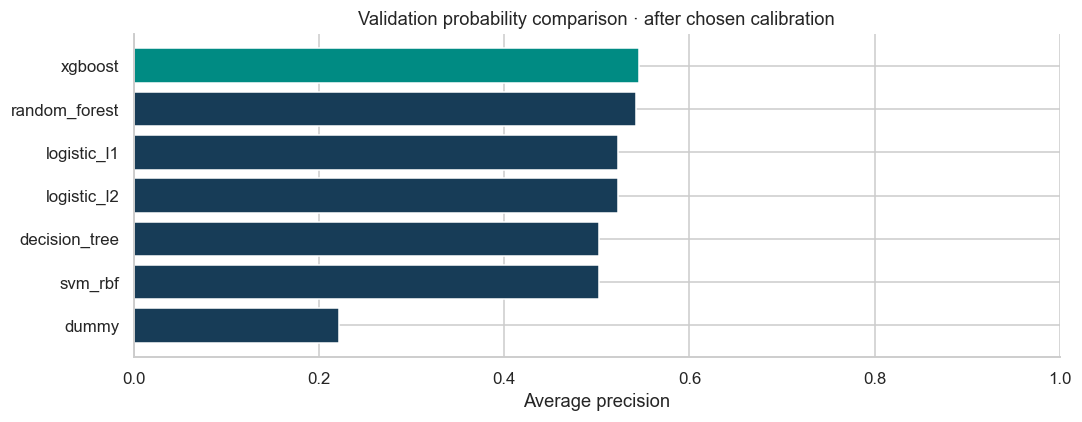

In [4]:
initial_selection = pd.Series(summary["model_selection"]["validation_average_precision"], name="selection_average_precision").sort_values(ascending=False)
display(initial_selection.to_frame())
validation_metrics = metrics.loc[metrics["split"].eq("validation") & ~metrics["model"].str.endswith("__policy")].sort_values("average_precision", ascending=False)
display(validation_metrics)
display(summary.get("calibration", {}))
fig, ax = plt.subplots(figsize=(10, 4))
ordered = validation_metrics.sort_values("average_precision")
ax.barh(ordered["model"], ordered["average_precision"], color=["#008b83" if m == winner else "#173c57" for m in ordered["model"]])
ax.set(xlabel="Average precision", title="Validation probability comparison · after chosen calibration", xlim=(0, 1))
plt.tight_layout()
plt.show()

## 3. Make the review-policy assumption explicit

The following laboratory uses **validation predictions only**. The cost formula is `false_negative_cost × FN + false_positive_cost × FP`; these are relative scenario units, not actual losses or savings. A threshold determines review workload, not the effectiveness of an intervention.

,threshold,review_share,precision,recall,false_alarms,missed_defaults,scenario_cost_units,policy
0,0.1500,0.4910,0.3547,0.7875,1901,282,"3,311.0000",Frozen validation selection
1,0.5000,0.1157,0.6484,0.3391,244,877,"4,629.0000",Reference 0.5


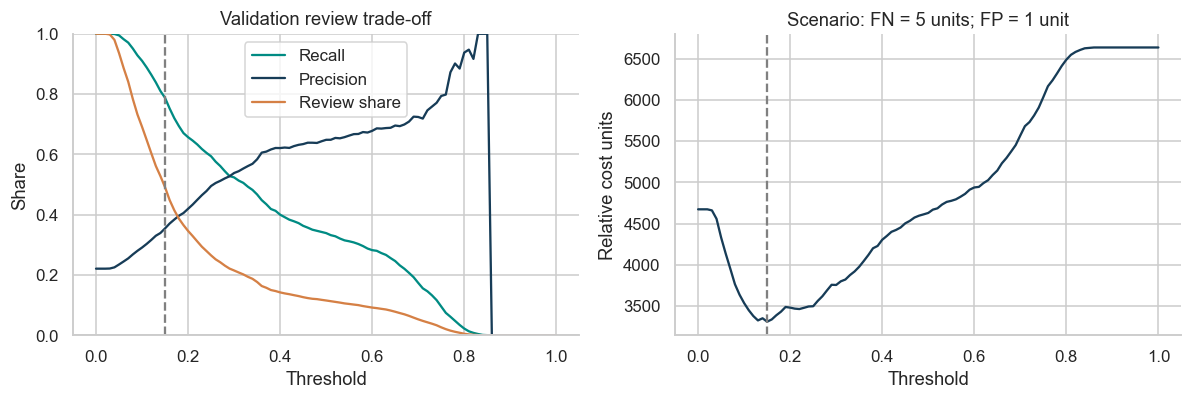

In [5]:
vp = validation_predictions.loc[validation_predictions.model.eq(winner)].copy()
assert len(vp) > 0 and vp.id.is_unique
assert set(vp.id) == set(manifest.loc[manifest["split"].eq("validation"), "id"])
y_val, p_val = vp.y_true.to_numpy(), vp.probability.to_numpy()

def policy_row(t, fn_cost=5.0, fp_cost=1.0):
    prediction = (p_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, prediction, labels=[0, 1]).ravel()
    return {"threshold": t, "review_share": prediction.mean(), "precision": precision_score(y_val, prediction, zero_division=0),
            "recall": recall_score(y_val, prediction, zero_division=0), "false_alarms": fp,
            "missed_defaults": fn, "scenario_cost_units": fn_cost * fn + fp_cost * fp}

policy = pd.DataFrame([policy_row(t) for t in np.unique(np.r_[np.linspace(0, 1, 101), threshold])])
display(pd.DataFrame([policy_row(threshold), policy_row(0.5)]).assign(policy=["Frozen validation selection", "Reference 0.5"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(policy.threshold, policy.recall, label="Recall", color="#008b83")
axes[0].plot(policy.threshold, policy.precision, label="Precision", color="#173c57")
axes[0].plot(policy.threshold, policy.review_share, label="Review share", color="#d58045")
axes[0].axvline(threshold, color="gray", linestyle="--")
axes[0].set(xlabel="Threshold", ylabel="Share", title="Validation review trade-off", ylim=(0, 1))
axes[0].legend()
axes[1].plot(policy.threshold, policy.scenario_cost_units, color="#173c57")
axes[1].axvline(threshold, color="gray", linestyle="--")
axes[1].set(xlabel="Threshold", ylabel="Relative cost units", title="Scenario: FN = 5 units; FP = 1 unit")
plt.tight_layout()
plt.show()

**Sensitivity question:** if the cost of missing an account increases, which direction should the threshold move? Explore it on validation predictions, then explain why choosing the cheapest scenario on the test partition would violate the final-evaluation boundary.

In [6]:
cost_sensitivity = []
for relative_fn_cost in [1, 2, 5, 10]:
    scenario = pd.DataFrame([policy_row(t, fn_cost=relative_fn_cost) for t in np.linspace(0, 1, 201)])
    best = scenario.sort_values(["scenario_cost_units", "threshold"], ascending=[True, False]).iloc[0]
    cost_sensitivity.append({"FN_cost": relative_fn_cost, "FP_cost": 1, **best.to_dict()})
display(pd.DataFrame(cost_sensitivity))

,FN_cost,FP_cost,threshold,review_share,precision,recall,false_alarms,missed_defaults,scenario_cost_units
0,1,1,0.3850,0.1490,0.6208,0.4182,339.0000,772.0000,"1,111.0000"
1,2,1,0.3600,0.1637,0.6059,0.4484,387.0000,732.0000,"1,851.0000"
2,5,1,0.1500,0.4910,0.3547,0.7875,"1,901.0000",282.0000,"3,311.0000"
3,10,1,0.0850,0.7595,0.2741,0.9412,"3,308.0000",78.0000,"4,088.0000"


## 4. Read the final test assessment without selecting again

The next table is retrospective reporting after the champion and policy were frozen. Candidate test comparisons are descriptive. They do not reopen selection, even if another row looks stronger. A `__policy` row uses the validation-selected threshold on the same probabilities; other rows use 0.5. Bootstrap intervals assess sampling variability for the frozen champion in this cohort; they do not include every source of development or future-population uncertainty.

In [7]:
test_metrics = metrics.loc[metrics["split"].eq("test")]
display(test_metrics)
display(summary.get("bootstrap95", {}))
tp = test_predictions.loc[test_predictions.model.eq(winner)].copy()
assert tp.id.is_unique
assert set(tp.id) == set(manifest.loc[manifest["split"].eq("test"), "id"])
assert set(tp.id).isdisjoint(vp.id)
display(pd.Series({"test_accounts": len(tp), "test_average_precision_recomputed": average_precision_score(tp.y_true, tp.probability),
                   "test_roc_auc_recomputed": roc_auc_score(tp.y_true, tp.probability),
                   "test_brier_recomputed": brier_score_loss(tp.y_true, tp.probability)}, name="artifact_consistency_check").to_frame())

,model,split,average_precision,roc_auc,brier,precision,recall,f1,threshold,tn,fp,fn,tp,review_rate,fpr
8,dummy,test,0.2212,0.5000,0.1723,0.0000,0.0000,0.0000,0.5000,4673,0,1327,0,0.0000,0.0000
9,logistic_l1,test,0.5538,0.7793,0.1342,0.6878,0.3685,0.4799,0.5000,4451,222,838,489,0.1185,0.0475
10,logistic_l2,test,0.5534,0.7792,0.1343,0.6887,0.3685,0.4801,0.5000,4452,221,838,489,0.1183,0.0473
11,decision_tree,test,0.5417,0.7749,0.1360,0.6795,0.3580,0.4689,0.5000,4449,224,852,475,0.1165,0.0479
12,random_forest,test,0.5705,0.7857,0.1330,0.6888,0.3602,0.4730,0.5000,4457,216,849,478,0.1157,0.0462
13,xgboost,test,0.5812,0.7928,0.1311,0.6880,0.3723,0.4831,0.5000,4449,224,833,494,0.1197,0.0479
14,xgboost__policy,test,0.5812,0.7928,0.1311,0.3614,0.7920,0.4963,0.1500,2816,1857,276,1051,0.4847,0.3974
15,svm_rbf,test,0.5335,0.7386,0.1426,0.7133,0.3188,0.4406,0.5000,4503,170,904,423,0.0988,0.0364


{'average_precision': {'low': 0.5510696620012159, 'high': 0.6073039261385187},
 'roc_auc': {'low': 0.7780179942185257, 'high': 0.8074965942725147},
 'brier': {'low': 0.1255251994616012, 'high': 0.13654451752596183},
 'recall': {'low': 0.7701560794213973, 'high': 0.8122903804742156},
 'precision': {'low': 0.34509571001778633, 'high': 0.37948219411263984},
 'f1': {'low': 0.4792833107133855, 'high': 0.5144341263853413}}

,artifact_consistency_check
test_accounts,"6,000.0000"
test_average_precision_recomputed,0.5812
test_roc_auc_recomputed,0.7928
test_brier_recomputed,0.1311


### Cost-optimal and capacity-limited review are different policies

The default threshold minimizes the stated validation error-cost scenario without constraining the number of reviews. It can therefore flag a large share of accounts. A team that can review only 10% needs a capacity rule. The fixed top-10% ranking benchmark below was defined separately; it was not selected by searching test outcomes. It describes which recorded defaults are concentrated in the highest-scoring accounts, not prevented defaults.

In [8]:
budget = summary["review_budget"]
fraction = float(budget["review_fraction"])
val_count = max(1, int(np.ceil(len(vp) * fraction)))
val_top = vp.sort_values("probability", ascending=False, kind="stable").head(val_count)
budget_comparison = pd.DataFrame([
    {"split": "validation", "review_fraction": fraction, "reviewed": val_count,
     "precision_at_budget": val_top.y_true.mean(),
     "recall_at_budget": val_top.y_true.sum() / vp.y_true.sum()},
    {"split": "test (frozen descriptive benchmark)", **budget},
])
display(budget_comparison)
display(pd.DataFrame([
    {"policy": "Frozen cost-selected threshold", "test_review_fraction": summary["test_metrics"]["review_rate"],
     "test_precision": summary["test_metrics"]["precision"], "test_recall": summary["test_metrics"]["recall"]},
    {"policy": "Fixed top-10% review benchmark", "test_review_fraction": fraction,
     "test_precision": budget["precision_at_budget"], "test_recall": budget["recall_at_budget"]},
]))

,split,review_fraction,reviewed,precision_at_budget,recall_at_budget
0,validation,0.1000,600,0.6683,0.3022
1,test (frozen descriptive benchmark),0.1000,600,0.7233,0.3271


,policy,test_review_fraction,test_precision,test_recall
0,Frozen cost-selected threshold,0.4847,0.3614,0.7920
1,Fixed top-10% review benchmark,0.1000,0.7233,0.3271


## 5. Probability, error, feature and subgroup diagnostics

The generated plots retain their cohort and split context. Calibration and confusion matrices answer different questions from a ranking score. Feature importance measures how the model uses information; it is not a causal explanation. Subgroup metrics need outcome counts and uncertainty, especially for smaller groups.

**roc_pr_curves.png**

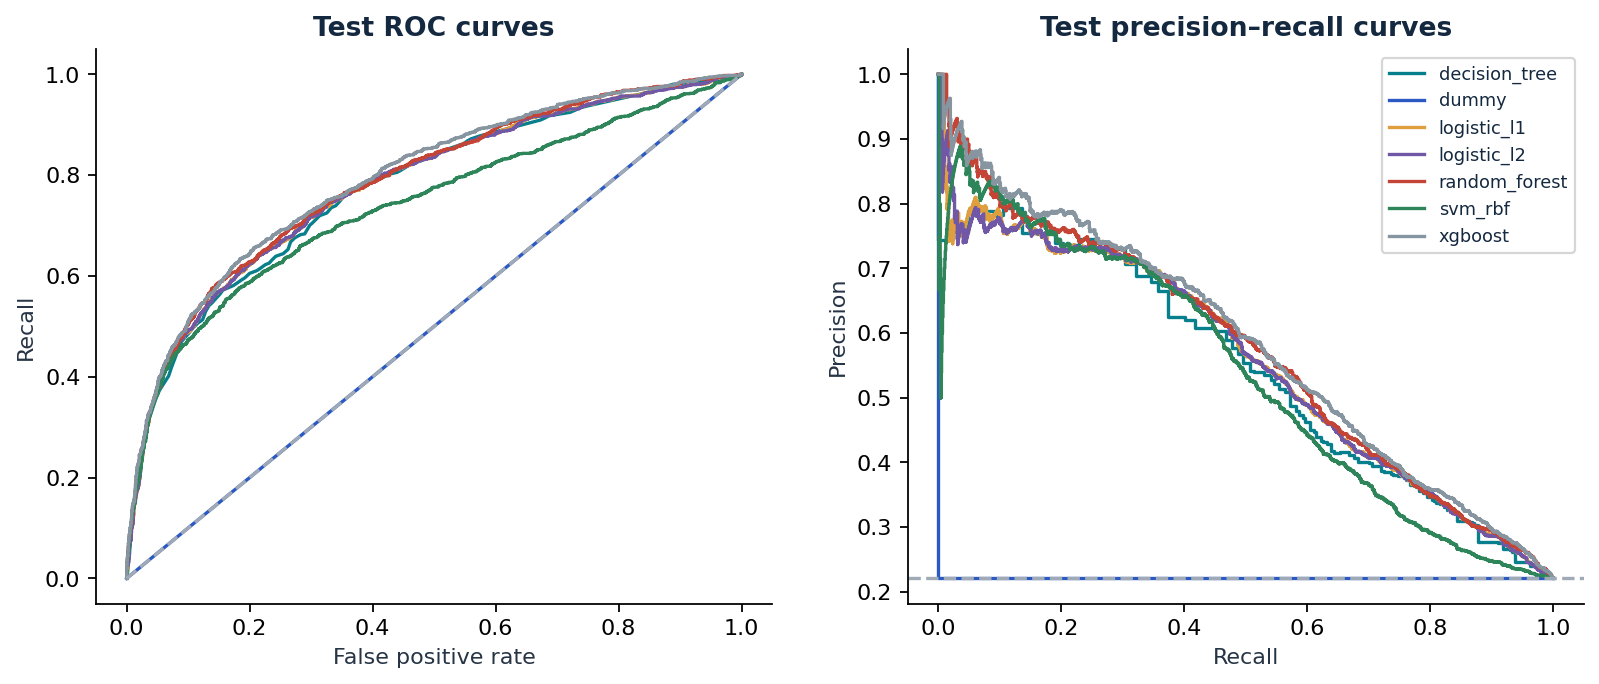

**calibration.png**

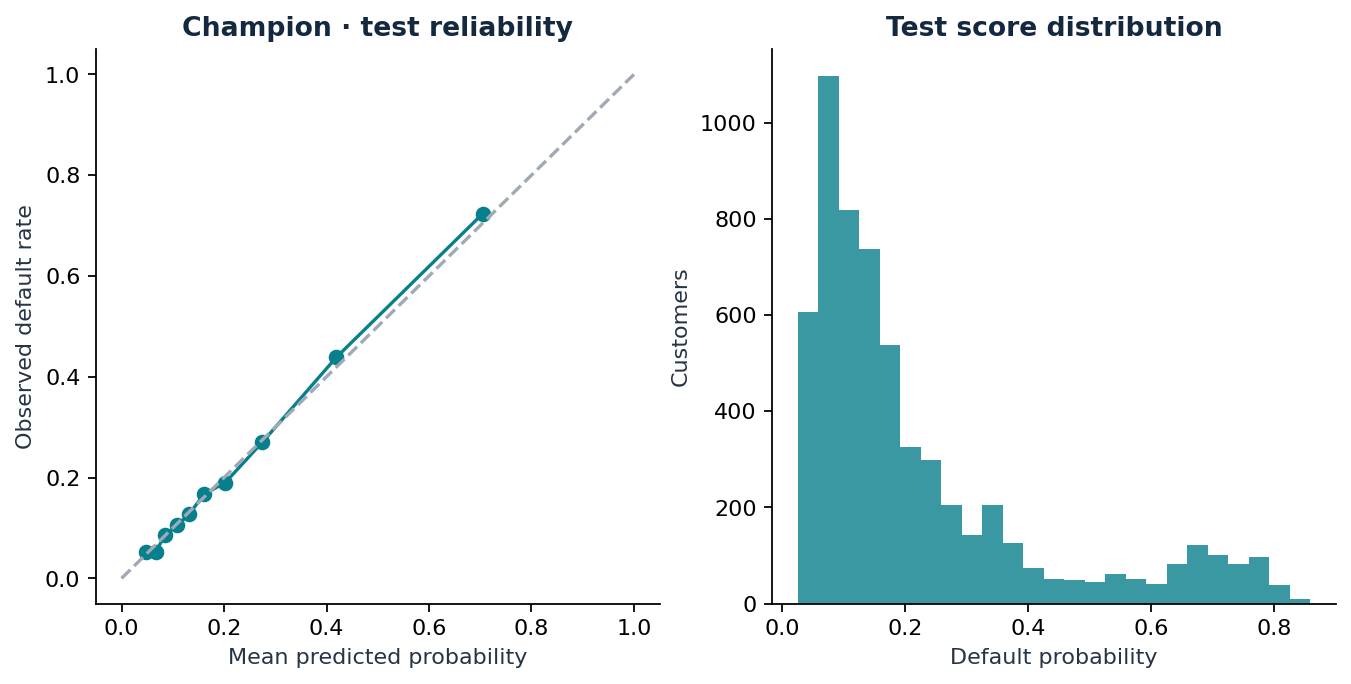

**confusion_matrix.png**

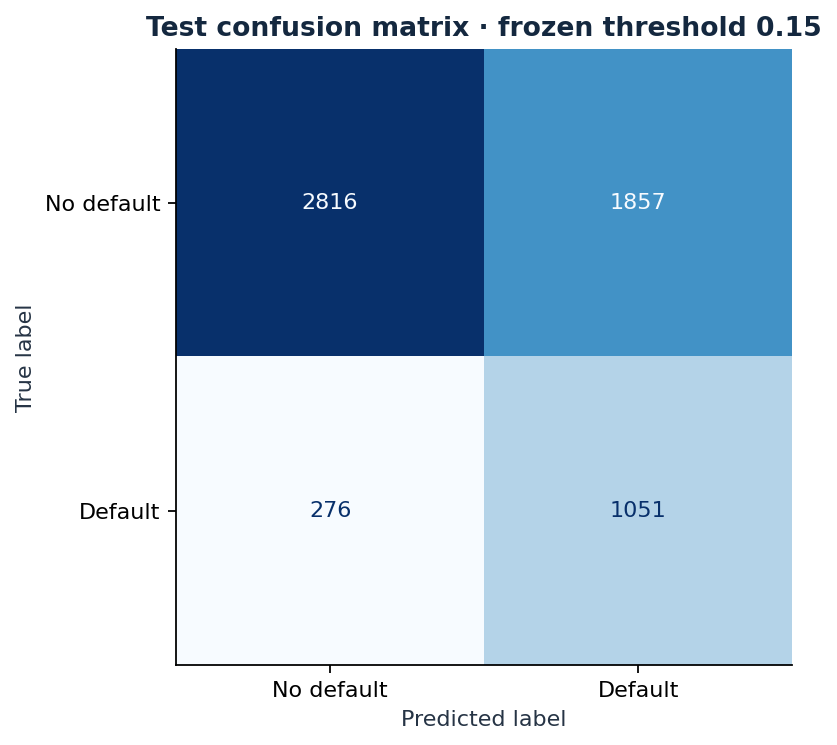

**feature_importance.png**

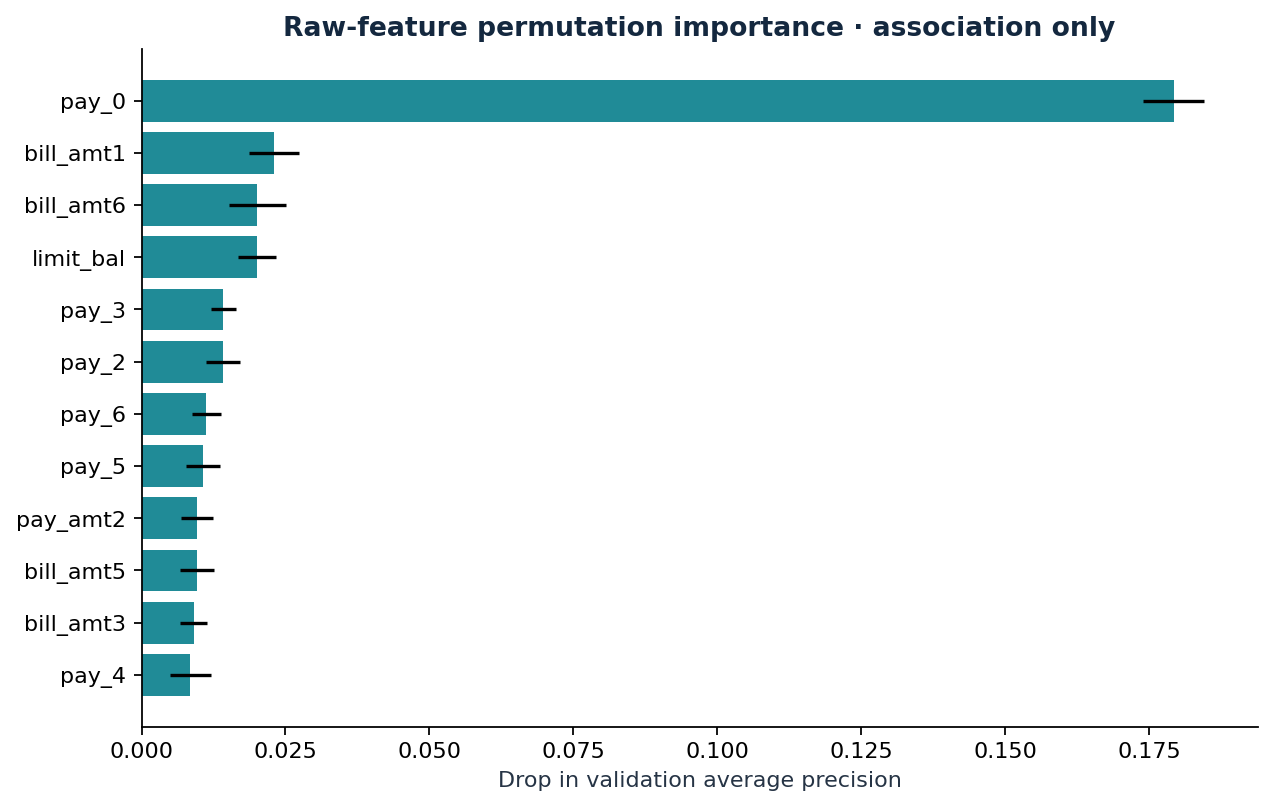

**subgroup_audit.png**

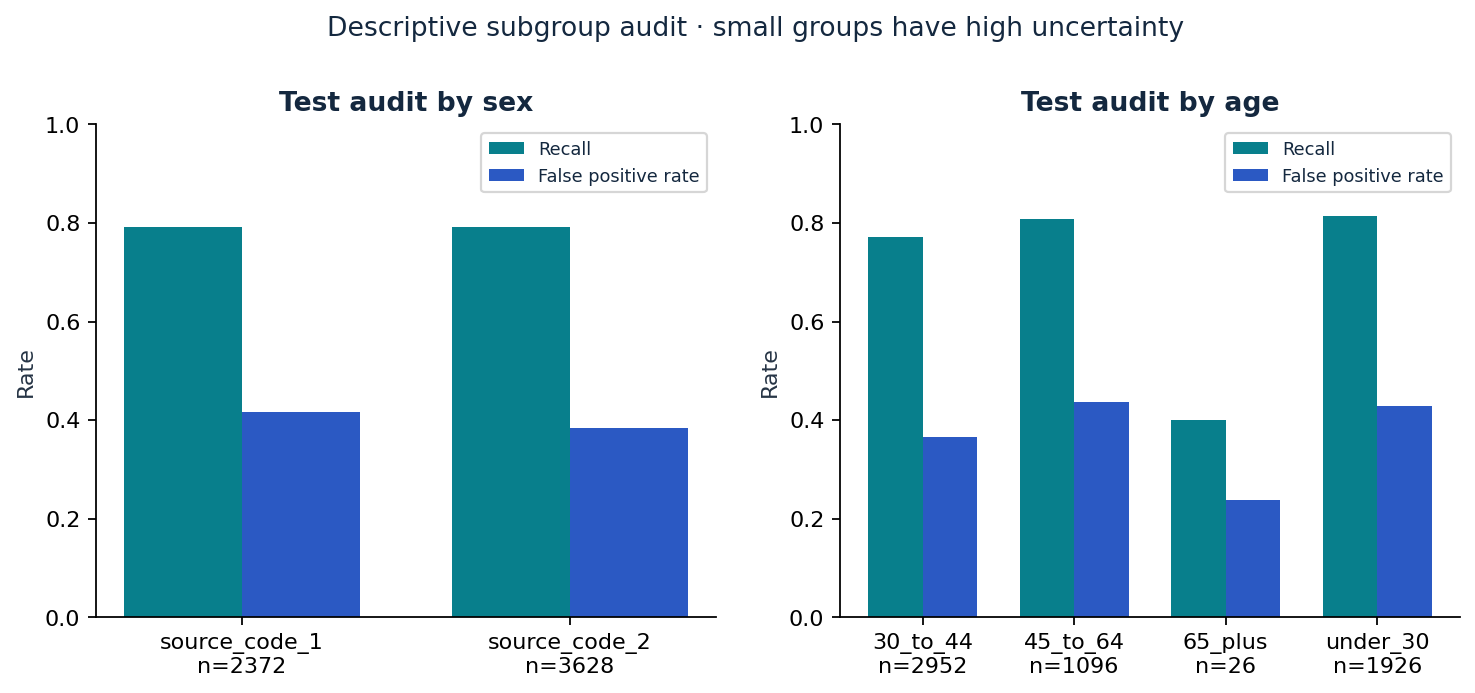

**feature_ablation.csv**

,features,mean_cv_average_precision,std_cv_average_precision,note
0,original_only,0.5562,0.0082,Training-only fixed-parameter exploratory comp...
1,original_plus_engineered,0.5632,0.0089,Training-only fixed-parameter exploratory comp...


**subgroup_metrics.csv**

,split,attribute,group,n,prevalence,average_precision,roc_auc,brier,precision,recall,f1,threshold,tn,fp,fn,tp,review_rate,fpr
0,test,sex,source_code_1,2372,0.2411,0.5693,0.7835,0.1439,0.3762,0.7920,0.5101,0.1500,1049,751,119,453,0.5076,0.4172
1,test,sex,source_code_2,3628,0.2081,0.5932,0.7982,0.1228,0.3509,0.7921,0.4864,0.1500,1767,1106,157,598,0.4697,0.3850
2,test,age,30_to_44,2952,0.2080,0.5751,0.7963,0.1246,0.3572,0.7720,0.4884,0.1500,1485,853,140,474,0.4495,0.3648
3,test,age,45_to_64,1096,0.2619,0.6168,0.7843,0.1494,0.3959,0.8084,0.5315,0.1500,455,354,55,232,0.5347,0.4376
4,test,age,65_plus,26,0.1923,0.3562,0.5429,0.1411,0.2857,0.4000,0.3333,0.1500,16,5,3,2,0.2692,0.2381
5,test,age,under_30,1926,0.2186,0.5727,0.7924,0.1306,0.3472,0.8147,0.4869,0.1500,860,645,78,343,0.5130,0.4286


In [9]:
for filename in ["roc_pr_curves.png", "calibration.png", "confusion_matrix.png",
                 "feature_importance.png", "subgroup_audit.png"]:
    path = ROOT / "reports/figures" / filename
    if path.exists():
        display(Markdown(f"**{filename}**"))
        display(Image(filename=str(path), width=1000))
for filename in ["feature_ablation.csv", "ablation.csv", "subgroup_metrics.csv"]:
    path = ROOT / "reports" / filename
    if path.exists():
        display(Markdown(f"**{filename}**"))
        display(pd.read_csv(path))

## 6. Deployment and feedback

Run `python app/dashboard.py` from the project root. The app loads the fitted champion and uses the same transformation pipeline. Its single-account example is fictional. If model binaries are absent in a fresh Git clone, rerun the training command; aggregate results remain available for review.

Read `docs/model_card.md` for intended use and limitations, `docs/results.md` for the findings, and `docs/feedback.md` for an honest review and monitoring plan. No stakeholder endorsement or production outcome is implied.

## Decision record

Before presenting this project, explain: (1) why the champion was selected, (2) whether probability calibration helped, (3) why the chosen threshold differs from 0.5, (4) where performance is weakest, (5) whether engineered features added value, and (6) what external evidence would be necessary before real-world use. Use the artifacts above to answer; do not infer success from model complexity.